In [1]:
import numpy as np
%pip install lime
import lime
import torch
from tokenizers import Tokenizer
from collections import OrderedDict
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools
from sklearn.metrics import precision_recall_fscore_support
from datasets import load_dataset, concatenate_datasets, DatasetDict


root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
topics = ["stance_abortion", "stance_atheism", "stance_climate", "stance_feminist", "stance_hillary"]

per_topic = [load_dataset("cardiffnlp/tweet_eval", t) for t in topics]

# all topics
dataset = DatasetDict({
    split: concatenate_datasets([ds[split] for ds in per_topic])
    for split in ["train", "validation", "test"]
})
# 1 topic
# dataset = per_topic[0]

dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})
# 1 topic
# dataset = load_dataset("cardiffnlp/tweet_eval", topics[0])

In [3]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [4]:
#tokenizer
vocab_size = 1000
min_frequency = 2
comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])
corpus = [text for text in comb_dataset["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [5]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [6]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [7]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [8]:
outcome_space = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [9]:
classifiers = OrderedDict()
MLP_PARAMS = {
    "hidden_dim": 128,
    "dropout": 0.1,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "num_epochs": 100,
}
LOGISTIC_PARAMS = {"max_iter": 100}
rope = 0.005


In [10]:
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [11]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args=LOGISTIC_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [12]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.288 seconds
Dataloader done! Time taken: 0.008 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0323 | train acc: 0.4770 | val loss: 1.0106 | val acc: 0.4786
Epoch 02 | train loss: 0.8939 | train acc: 0.5474 | val loss: 0.9373 | val acc: 0.5369


/Users/mac/Documents/GitHub/NLP1/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/mac/Documents/GitHub/NLP1/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 03 | train loss: 0.7274 | train acc: 0.7211 | val loss: 0.9003 | val acc: 0.5798
Epoch 04 | train loss: 0.5765 | train acc: 0.7962 | val loss: 0.9036 | val acc: 0.5901
Epoch 05 | train loss: 0.4654 | train acc: 0.8494 | val loss: 0.9299 | val acc: 0.5935
Epoch 06 | train loss: 0.3731 | train acc: 0.8919 | val loss: 0.9859 | val acc: 0.5883
Epoch 07 | train loss: 0.2988 | train acc: 0.9236 | val loss: 1.0173 | val acc: 0.5901
Epoch 08 | train loss: 0.2429 | train acc: 0.9498 | val loss: 1.0800 | val acc: 0.5935
Epoch 09 | train loss: 0.1930 | train acc: 0.9713 | val loss: 1.1383 | val acc: 0.5883
Epoch 10 | train loss: 0.1573 | train acc: 0.9820 | val loss: 1.1866 | val acc: 0.5935
Epoch 11 | train loss: 0.1264 | train acc: 0.9901 | val loss: 1.2554 | val acc: 0.5849
Epoch 12 | train loss: 0.1050 | train acc: 0.9923 | val loss: 1.2828 | val acc: 0.5883
Epoch 13 | train loss: 0.0844 | train acc: 0.9966 | val loss: 1.3362 | val acc: 0.5918
Epoch 14 | train loss: 0.0711 | train acc: 

... (4 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0423 | train acc: 0.4758 | val loss: 1.0083 | val acc: 0.4734
Epoch 02 | train loss: 0.9119 | train acc: 0.5337 | val loss: 0.9274 | val acc: 0.5678
Epoch 03 | train loss: 0.7474 | train acc: 0.7023 | val loss: 0.8761 | val acc: 0.6055
Epoch 04 | train loss: 0.5972 | train acc: 0.7954 | val loss: 0.8421 | val acc: 0.6141
Epoch 05 | train loss: 0.4753 | train acc: 0.8546 | val loss: 0.8660 | val acc: 0.6226
Epoch 06 | train loss: 0.3831 | train acc: 0.8945 | val loss: 0.8877 | val acc: 0.6244
Epoch 07 | train loss: 0.3083 | train acc: 0.9249 | val loss: 0.9319 | val acc: 0.6141
Epoch 08 | train loss: 0.2406 | train acc: 0.9562 | val loss: 0.9530 | val acc: 0.6192
Epoch 09 | train loss: 0.1932 | train acc: 0.9764 | val loss: 1.0022 | val acc: 0.6226
Epoch 10 | train loss: 0.1533 | train acc: 0.9841 | val loss: 1.0391 | val acc: 0.6295
Epoch 11 | train loss: 0.1201 | train acc: 0.9927 | val loss: 1.0905 | val acc: 0.6158
Epoch 12 | train loss: 0.0986 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0430 | train acc: 0.4721 | val loss: 1.0207 | val acc: 0.4691
Epoch 02 | train loss: 0.9112 | train acc: 0.5437 | val loss: 0.9482 | val acc: 0.5361
Epoch 03 | train loss: 0.7436 | train acc: 0.7204 | val loss: 0.8948 | val acc: 0.5670
Epoch 04 | train loss: 0.5944 | train acc: 0.7907 | val loss: 0.8834 | val acc: 0.5876
Epoch 05 | train loss: 0.4754 | train acc: 0.8499 | val loss: 0.9016 | val acc: 0.5928
Epoch 06 | train loss: 0.3786 | train acc: 0.8911 | val loss: 0.9382 | val acc: 0.6031
Epoch 07 | train loss: 0.3042 | train acc: 0.9284 | val loss: 0.9774 | val acc: 0.5928
Epoch 08 | train loss: 0.2444 | train acc: 0.9533 | val loss: 1.0242 | val acc: 0.6048
Epoch 09 | train loss: 0.1954 | train acc: 0.9670 | val loss: 1.0717 | val acc: 0.5808
Epoch 10 | train loss: 0.1561 | train acc: 0.9824 | val loss: 1.1154 | val acc: 0.5808
Epoch 11 | train loss: 0.1249 | train acc: 0.9897 | val loss: 1.1672 | val acc: 0.5859
Epoch 12 | train loss: 0.1051 | train acc: 

In [13]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.319 seconds
Dataloader done! Time taken: 0.009 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0482 | train acc: 0.4590 | val loss: 1.0333 | val acc: 0.4751
Epoch 02 | train loss: 0.9258 | train acc: 0.5131 | val loss: 0.9340 | val acc: 0.5437
Epoch 03 | train loss: 0.6576 | train acc: 0.7340 | val loss: 0.9316 | val acc: 0.6003
Epoch 04 | train loss: 0.3759 | train acc: 0.8589 | val loss: 1.1493 | val acc: 0.5832
Epoch 05 | train loss: 0.1894 | train acc: 0.9520 | val loss: 1.3238 | val acc: 0.5780
Epoch 06 | train loss: 0.0840 | train acc: 0.9858 | val loss: 1.5005 | val acc: 0.5609
Epoch 07 | train loss: 0.0405 | train acc: 0.9949 | val loss: 1.7240 | val acc: 0.5763
Epoch 08 | train loss: 0.0247 | train acc: 0.9983 | val loss: 1.8307 | val acc: 0.5729
Epoch 09 | train loss: 0.0170 | train acc: 0.9983 | val loss: 1.9420 | val acc: 0.5626
Epoch 10 | train loss: 0.0118 | train acc: 0.9983 | val loss: 2.0441 | val acc: 0.5626
Epoch 11 | train loss: 0.0093 | train acc: 0.9983 | val loss: 2.1444 | val acc: 0.5763
Epoch 12 | train loss: 0.0067 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0504 | train acc: 0.4672 | val loss: 1.0152 | val acc: 0.5026
Epoch 02 | train loss: 0.9286 | train acc: 0.5131 | val loss: 0.9194 | val acc: 0.5609
Epoch 03 | train loss: 0.6545 | train acc: 0.7310 | val loss: 0.9503 | val acc: 0.5815
Epoch 04 | train loss: 0.3882 | train acc: 0.8657 | val loss: 1.0696 | val acc: 0.5746
Epoch 05 | train loss: 0.2005 | train acc: 0.9455 | val loss: 1.2749 | val acc: 0.5712
Epoch 06 | train loss: 0.0953 | train acc: 0.9820 | val loss: 1.4704 | val acc: 0.5815
Epoch 07 | train loss: 0.0445 | train acc: 0.9953 | val loss: 1.6543 | val acc: 0.5660
Epoch 08 | train loss: 0.0266 | train acc: 0.9966 | val loss: 1.7859 | val acc: 0.5695
Epoch 09 | train loss: 0.0182 | train acc: 0.9974 | val loss: 1.9022 | val acc: 0.5575
Epoch 10 | train loss: 0.0131 | train acc: 0.9983 | val loss: 1.9928 | val acc: 0.5849
Epoch 11 | train loss: 0.0124 | train acc: 0.9983 | val loss: 2.0616 | val acc: 0.5832
Epoch 12 | train loss: 0.0081 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0445 | train acc: 0.4822 | val loss: 1.0248 | val acc: 0.4648
Epoch 02 | train loss: 0.9107 | train acc: 0.5470 | val loss: 0.9515 | val acc: 0.5369
Epoch 03 | train loss: 0.6456 | train acc: 0.7452 | val loss: 0.8919 | val acc: 0.5986
Epoch 04 | train loss: 0.3770 | train acc: 0.8752 | val loss: 1.0140 | val acc: 0.6141
Epoch 05 | train loss: 0.1890 | train acc: 0.9545 | val loss: 1.1722 | val acc: 0.6003
Epoch 06 | train loss: 0.0824 | train acc: 0.9884 | val loss: 1.3623 | val acc: 0.6055
Epoch 07 | train loss: 0.0381 | train acc: 0.9974 | val loss: 1.5032 | val acc: 0.6038
Epoch 08 | train loss: 0.0220 | train acc: 0.9974 | val loss: 1.6051 | val acc: 0.6055
Epoch 09 | train loss: 0.0129 | train acc: 0.9996 | val loss: 1.6999 | val acc: 0.6003
Epoch 10 | train loss: 0.0117 | train acc: 0.9991 | val loss: 1.8157 | val acc: 0.6106
Epoch 11 | train loss: 0.0102 | train acc: 0.9987 | val loss: 1.8254 | val acc: 0.5986
Epoch 12 | train loss: 0.0070 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0447 | train acc: 0.4816 | val loss: 1.0316 | val acc: 0.4691
Epoch 02 | train loss: 0.9142 | train acc: 0.5292 | val loss: 0.9300 | val acc: 0.5584
Epoch 03 | train loss: 0.6358 | train acc: 0.7543 | val loss: 0.9422 | val acc: 0.5962
Epoch 04 | train loss: 0.3731 | train acc: 0.8774 | val loss: 1.0562 | val acc: 0.6168
Epoch 05 | train loss: 0.1945 | train acc: 0.9494 | val loss: 1.2386 | val acc: 0.5928
Epoch 06 | train loss: 0.0857 | train acc: 0.9841 | val loss: 1.4036 | val acc: 0.5790
Epoch 07 | train loss: 0.0420 | train acc: 0.9944 | val loss: 1.5387 | val acc: 0.5945
Epoch 08 | train loss: 0.0238 | train acc: 0.9974 | val loss: 1.7044 | val acc: 0.5945
Epoch 09 | train loss: 0.0150 | train acc: 0.9983 | val loss: 1.8341 | val acc: 0.5945
Epoch 10 | train loss: 0.0109 | train acc: 0.9991 | val loss: 1.9026 | val acc: 0.5997
Epoch 11 | train loss: 0.0080 | train acc: 0.9991 | val loss: 1.9568 | val acc: 0.6117
Epoch 12 | train loss: 0.0061 | train acc: 

In [14]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args=LOGISTIC_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [15]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.310 seconds
Dataloader done! Time taken: 0.009 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0347 | train acc: 0.4732 | val loss: 1.0187 | val acc: 0.4768
Epoch 02 | train loss: 0.9007 | train acc: 0.5573 | val loss: 0.9571 | val acc: 0.5369
Epoch 03 | train loss: 0.7366 | train acc: 0.7242 | val loss: 0.9203 | val acc: 0.5643
Epoch 04 | train loss: 0.5815 | train acc: 0.7975 | val loss: 0.9376 | val acc: 0.5575
Epoch 05 | train loss: 0.4653 | train acc: 0.8498 | val loss: 0.9554 | val acc: 0.5883
Epoch 06 | train loss: 0.3671 | train acc: 0.8932 | val loss: 1.0067 | val acc: 0.5780
Epoch 07 | train loss: 0.2937 | train acc: 0.9309 | val loss: 1.0676 | val acc: 0.5695
Epoch 08 | train loss: 0.2320 | train acc: 0.9575 | val loss: 1.1115 | val acc: 0.5746
Epoch 09 | train loss: 0.1812 | train acc: 0.9747 | val loss: 1.1777 | val acc: 0.5660
Epoch 10 | train loss: 0.1477 | train acc: 0.9816 | val loss: 1.2201 | val acc: 0.5866
Epoch 11 | train loss: 0.1164 | train acc: 0.9918 | val loss: 1.2742 | val acc: 0.5780
Epoch 12 | train loss: 0.0944 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0367 | train acc: 0.4668 | val loss: 0.9851 | val acc: 0.5043
Epoch 02 | train loss: 0.8936 | train acc: 0.5633 | val loss: 0.9214 | val acc: 0.5609
Epoch 03 | train loss: 0.7200 | train acc: 0.7160 | val loss: 0.8977 | val acc: 0.5660
Epoch 04 | train loss: 0.5798 | train acc: 0.7932 | val loss: 0.8966 | val acc: 0.5695
Epoch 05 | train loss: 0.4686 | train acc: 0.8477 | val loss: 0.9222 | val acc: 0.5746
Epoch 06 | train loss: 0.3715 | train acc: 0.8945 | val loss: 0.9648 | val acc: 0.5626
Epoch 07 | train loss: 0.3000 | train acc: 0.9258 | val loss: 1.0124 | val acc: 0.5626
Epoch 08 | train loss: 0.2422 | train acc: 0.9498 | val loss: 1.0620 | val acc: 0.5746
Epoch 09 | train loss: 0.1899 | train acc: 0.9691 | val loss: 1.1183 | val acc: 0.5695
Epoch 10 | train loss: 0.1532 | train acc: 0.9816 | val loss: 1.1683 | val acc: 0.5746
Epoch 11 | train loss: 0.1226 | train acc: 0.9893 | val loss: 1.2201 | val acc: 0.5763
Epoch 12 | train loss: 0.1019 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0377 | train acc: 0.4753 | val loss: 1.0102 | val acc: 0.4717
Epoch 02 | train loss: 0.8977 | train acc: 0.5594 | val loss: 0.9460 | val acc: 0.5300
Epoch 03 | train loss: 0.7409 | train acc: 0.7096 | val loss: 0.8929 | val acc: 0.5969
Epoch 04 | train loss: 0.5910 | train acc: 0.7773 | val loss: 0.8778 | val acc: 0.6038
Epoch 05 | train loss: 0.4745 | train acc: 0.8503 | val loss: 0.8985 | val acc: 0.6106
Epoch 06 | train loss: 0.3782 | train acc: 0.8936 | val loss: 0.9216 | val acc: 0.6038
Epoch 07 | train loss: 0.3003 | train acc: 0.9301 | val loss: 0.9708 | val acc: 0.6055
Epoch 08 | train loss: 0.2400 | train acc: 0.9554 | val loss: 0.9898 | val acc: 0.5986
Epoch 09 | train loss: 0.1884 | train acc: 0.9747 | val loss: 1.0666 | val acc: 0.6055
Epoch 10 | train loss: 0.1507 | train acc: 0.9863 | val loss: 1.0918 | val acc: 0.6158
Epoch 11 | train loss: 0.1213 | train acc: 0.9918 | val loss: 1.1498 | val acc: 0.6072
Epoch 12 | train loss: 0.0977 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0415 | train acc: 0.4657 | val loss: 1.0164 | val acc: 0.4674
Epoch 02 | train loss: 0.9045 | train acc: 0.5412 | val loss: 0.9471 | val acc: 0.5275
Epoch 03 | train loss: 0.7481 | train acc: 0.7217 | val loss: 0.8945 | val acc: 0.5739
Epoch 04 | train loss: 0.5929 | train acc: 0.7959 | val loss: 0.8902 | val acc: 0.5893
Epoch 05 | train loss: 0.4719 | train acc: 0.8533 | val loss: 0.9082 | val acc: 0.5808
Epoch 06 | train loss: 0.3715 | train acc: 0.9069 | val loss: 0.9475 | val acc: 0.5928
Epoch 07 | train loss: 0.2923 | train acc: 0.9352 | val loss: 0.9815 | val acc: 0.5876
Epoch 08 | train loss: 0.2335 | train acc: 0.9541 | val loss: 1.0214 | val acc: 0.6117
Epoch 09 | train loss: 0.1779 | train acc: 0.9764 | val loss: 1.0746 | val acc: 0.5911
Epoch 10 | train loss: 0.1460 | train acc: 0.9854 | val loss: 1.1149 | val acc: 0.5997
Epoch 11 | train loss: 0.1168 | train acc: 0.9889 | val loss: 1.1601 | val acc: 0.5962
Epoch 12 | train loss: 0.0922 | train acc: 

In [16]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.311 seconds
Dataloader done! Time taken: 0.009 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0434 | train acc: 0.4801 | val loss: 1.0249 | val acc: 0.4751
Epoch 02 | train loss: 0.9090 | train acc: 0.5315 | val loss: 0.9334 | val acc: 0.5540
Epoch 03 | train loss: 0.6438 | train acc: 0.7525 | val loss: 0.9649 | val acc: 0.5763
Epoch 04 | train loss: 0.3803 | train acc: 0.8743 | val loss: 1.1479 | val acc: 0.5712
Epoch 05 | train loss: 0.1960 | train acc: 0.9468 | val loss: 1.3441 | val acc: 0.5678
Epoch 06 | train loss: 0.0870 | train acc: 0.9867 | val loss: 1.5548 | val acc: 0.5746
Epoch 07 | train loss: 0.0459 | train acc: 0.9957 | val loss: 1.6968 | val acc: 0.5660
Epoch 08 | train loss: 0.0273 | train acc: 0.9970 | val loss: 1.8682 | val acc: 0.5832
Epoch 09 | train loss: 0.0193 | train acc: 0.9974 | val loss: 2.0060 | val acc: 0.5746
Epoch 10 | train loss: 0.0150 | train acc: 0.9983 | val loss: 2.0418 | val acc: 0.5678
Epoch 11 | train loss: 0.0095 | train acc: 0.9987 | val loss: 2.2185 | val acc: 0.5815
Epoch 12 | train loss: 0.0070 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0594 | train acc: 0.4543 | val loss: 1.0159 | val acc: 0.5026
Epoch 02 | train loss: 0.9478 | train acc: 0.4912 | val loss: 0.9187 | val acc: 0.5420
Epoch 03 | train loss: 0.6915 | train acc: 0.7272 | val loss: 0.9555 | val acc: 0.5575
Epoch 04 | train loss: 0.4100 | train acc: 0.8537 | val loss: 1.0746 | val acc: 0.5678
Epoch 05 | train loss: 0.2187 | train acc: 0.9429 | val loss: 1.2981 | val acc: 0.5678
Epoch 06 | train loss: 0.1037 | train acc: 0.9794 | val loss: 1.4495 | val acc: 0.5609
Epoch 07 | train loss: 0.0454 | train acc: 0.9927 | val loss: 1.6332 | val acc: 0.5729
Epoch 08 | train loss: 0.0293 | train acc: 0.9974 | val loss: 1.7803 | val acc: 0.5712
Epoch 09 | train loss: 0.0157 | train acc: 0.9991 | val loss: 1.8843 | val acc: 0.5746
Epoch 10 | train loss: 0.0139 | train acc: 0.9983 | val loss: 1.9617 | val acc: 0.5712
Epoch 11 | train loss: 0.0127 | train acc: 0.9987 | val loss: 2.0389 | val acc: 0.5678
Epoch 12 | train loss: 0.0112 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0459 | train acc: 0.4736 | val loss: 1.0248 | val acc: 0.4648
Epoch 02 | train loss: 0.9169 | train acc: 0.5255 | val loss: 0.9309 | val acc: 0.5472
Epoch 03 | train loss: 0.6673 | train acc: 0.7323 | val loss: 0.9449 | val acc: 0.5832
Epoch 04 | train loss: 0.4072 | train acc: 0.8580 | val loss: 1.0547 | val acc: 0.5780
Epoch 05 | train loss: 0.2155 | train acc: 0.9425 | val loss: 1.1596 | val acc: 0.5866
Epoch 06 | train loss: 0.0995 | train acc: 0.9807 | val loss: 1.3473 | val acc: 0.5883
Epoch 07 | train loss: 0.0470 | train acc: 0.9936 | val loss: 1.5017 | val acc: 0.5849
Epoch 08 | train loss: 0.0244 | train acc: 0.9991 | val loss: 1.6859 | val acc: 0.5952
Epoch 09 | train loss: 0.0161 | train acc: 0.9983 | val loss: 1.8124 | val acc: 0.5935
Epoch 10 | train loss: 0.0102 | train acc: 0.9996 | val loss: 1.9110 | val acc: 0.5866
Epoch 11 | train loss: 0.0097 | train acc: 0.9983 | val loss: 1.9653 | val acc: 0.5866
Epoch 12 | train loss: 0.0085 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0515 | train acc: 0.4597 | val loss: 1.0241 | val acc: 0.4691
Epoch 02 | train loss: 0.9292 | train acc: 0.5146 | val loss: 0.9185 | val acc: 0.5447
Epoch 03 | train loss: 0.6595 | train acc: 0.7410 | val loss: 0.9036 | val acc: 0.5945
Epoch 04 | train loss: 0.3865 | train acc: 0.8718 | val loss: 0.9851 | val acc: 0.6014
Epoch 05 | train loss: 0.1883 | train acc: 0.9503 | val loss: 1.2032 | val acc: 0.5928
Epoch 06 | train loss: 0.0797 | train acc: 0.9901 | val loss: 1.3752 | val acc: 0.6082
Epoch 07 | train loss: 0.0416 | train acc: 0.9949 | val loss: 1.4989 | val acc: 0.6203
Epoch 08 | train loss: 0.0233 | train acc: 0.9979 | val loss: 1.6058 | val acc: 0.6186
Epoch 09 | train loss: 0.0136 | train acc: 0.9996 | val loss: 1.7137 | val acc: 0.6203
Epoch 10 | train loss: 0.0106 | train acc: 0.9996 | val loss: 1.7917 | val acc: 0.6117
Epoch 11 | train loss: 0.0089 | train acc: 0.9987 | val loss: 1.8401 | val acc: 0.6117
Epoch 12 | train loss: 0.0070 | train acc: 

In [17]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args=LOGISTIC_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWar

In [18]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.323 seconds
Dataloader done! Time taken: 0.010 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0714 | train acc: 0.4543 | val loss: 1.0456 | val acc: 0.4751
Epoch 02 | train loss: 1.0179 | train acc: 0.4796 | val loss: 1.0229 | val acc: 0.4751
Epoch 03 | train loss: 0.9604 | train acc: 0.4865 | val loss: 0.9826 | val acc: 0.4871
Epoch 04 | train loss: 0.8688 | train acc: 0.5779 | val loss: 0.9346 | val acc: 0.5660
Epoch 05 | train loss: 0.7676 | train acc: 0.7297 | val loss: 0.9062 | val acc: 0.5660
Epoch 06 | train loss: 0.6827 | train acc: 0.7675 | val loss: 0.8945 | val acc: 0.5935
Epoch 07 | train loss: 0.6150 | train acc: 0.7898 | val loss: 0.8955 | val acc: 0.5935
Epoch 08 | train loss: 0.5616 | train acc: 0.8018 | val loss: 0.9055 | val acc: 0.5849
Epoch 09 | train loss: 0.5176 | train acc: 0.8241 | val loss: 0.9263 | val acc: 0.5763
Epoch 10 | train loss: 0.4860 | train acc: 0.8327 | val loss: 0.9412 | val acc: 0.5849
Epoch 11 | train loss: 0.4534 | train acc: 0.8520 | val loss: 0.9692 | val acc: 0.5798
Epoch 12 | train loss: 0.4235 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0703 | train acc: 0.4723 | val loss: 1.0349 | val acc: 0.5026
Epoch 02 | train loss: 1.0244 | train acc: 0.4728 | val loss: 1.0042 | val acc: 0.5026
Epoch 03 | train loss: 0.9685 | train acc: 0.4831 | val loss: 0.9621 | val acc: 0.5146
Epoch 04 | train loss: 0.8769 | train acc: 0.5779 | val loss: 0.9169 | val acc: 0.5695
Epoch 05 | train loss: 0.7748 | train acc: 0.7229 | val loss: 0.8793 | val acc: 0.5798
Epoch 06 | train loss: 0.6872 | train acc: 0.7550 | val loss: 0.8727 | val acc: 0.5883
Epoch 07 | train loss: 0.6181 | train acc: 0.7898 | val loss: 0.8774 | val acc: 0.5815
Epoch 08 | train loss: 0.5661 | train acc: 0.7924 | val loss: 0.8964 | val acc: 0.5626
Epoch 09 | train loss: 0.5220 | train acc: 0.8215 | val loss: 0.9127 | val acc: 0.5712
Epoch 10 | train loss: 0.4856 | train acc: 0.8331 | val loss: 0.9354 | val acc: 0.5643
Epoch 11 | train loss: 0.4567 | train acc: 0.8438 | val loss: 0.9628 | val acc: 0.5660
Epoch 12 | train loss: 0.4288 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0720 | train acc: 0.4535 | val loss: 1.0515 | val acc: 0.4648
Epoch 02 | train loss: 1.0171 | train acc: 0.4822 | val loss: 1.0281 | val acc: 0.4648
Epoch 03 | train loss: 0.9621 | train acc: 0.4925 | val loss: 0.9858 | val acc: 0.4871
Epoch 04 | train loss: 0.8760 | train acc: 0.5886 | val loss: 0.9356 | val acc: 0.5609
Epoch 05 | train loss: 0.7783 | train acc: 0.6864 | val loss: 0.8965 | val acc: 0.6038
Epoch 06 | train loss: 0.6941 | train acc: 0.7452 | val loss: 0.8845 | val acc: 0.5918
Epoch 07 | train loss: 0.6272 | train acc: 0.7726 | val loss: 0.8782 | val acc: 0.5901
Epoch 08 | train loss: 0.5737 | train acc: 0.7988 | val loss: 0.8784 | val acc: 0.6021
Epoch 09 | train loss: 0.5314 | train acc: 0.8108 | val loss: 0.8923 | val acc: 0.5935
Epoch 10 | train loss: 0.4937 | train acc: 0.8280 | val loss: 0.9029 | val acc: 0.6021
Epoch 11 | train loss: 0.4649 | train acc: 0.8374 | val loss: 0.9202 | val acc: 0.6055
Epoch 12 | train loss: 0.4338 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0662 | train acc: 0.4811 | val loss: 1.0494 | val acc: 0.4691
Epoch 02 | train loss: 1.0188 | train acc: 0.4811 | val loss: 1.0255 | val acc: 0.4691
Epoch 03 | train loss: 0.9640 | train acc: 0.4880 | val loss: 0.9848 | val acc: 0.4794
Epoch 04 | train loss: 0.8745 | train acc: 0.5785 | val loss: 0.9342 | val acc: 0.5447
Epoch 05 | train loss: 0.7717 | train acc: 0.7024 | val loss: 0.8991 | val acc: 0.5962
Epoch 06 | train loss: 0.6861 | train acc: 0.7543 | val loss: 0.8857 | val acc: 0.5962
Epoch 07 | train loss: 0.6138 | train acc: 0.7886 | val loss: 0.8949 | val acc: 0.5928
Epoch 08 | train loss: 0.5622 | train acc: 0.7985 | val loss: 0.9039 | val acc: 0.5842
Epoch 09 | train loss: 0.5165 | train acc: 0.8238 | val loss: 0.9224 | val acc: 0.5979
Epoch 10 | train loss: 0.4846 | train acc: 0.8375 | val loss: 0.9395 | val acc: 0.5893
Epoch 11 | train loss: 0.4496 | train acc: 0.8542 | val loss: 0.9659 | val acc: 0.5859
Epoch 12 | train loss: 0.4245 | train acc: 

In [19]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.334 seconds
Dataloader done! Time taken: 0.010 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0751 | train acc: 0.4093 | val loss: 1.0426 | val acc: 0.4751
Epoch 02 | train loss: 1.0091 | train acc: 0.4796 | val loss: 1.0046 | val acc: 0.4751
Epoch 03 | train loss: 0.9038 | train acc: 0.5285 | val loss: 0.9435 | val acc: 0.5540
Epoch 04 | train loss: 0.7469 | train acc: 0.7126 | val loss: 0.9288 | val acc: 0.5540
Epoch 05 | train loss: 0.5721 | train acc: 0.7932 | val loss: 0.9671 | val acc: 0.5712
Epoch 06 | train loss: 0.4324 | train acc: 0.8529 | val loss: 1.0561 | val acc: 0.5643
Epoch 07 | train loss: 0.3284 | train acc: 0.8923 | val loss: 1.1739 | val acc: 0.5592
Epoch 08 | train loss: 0.2433 | train acc: 0.9275 | val loss: 1.3368 | val acc: 0.5455
Epoch 09 | train loss: 0.1775 | train acc: 0.9605 | val loss: 1.4513 | val acc: 0.5660
Epoch 10 | train loss: 0.1161 | train acc: 0.9790 | val loss: 1.6213 | val acc: 0.5695
Epoch 11 | train loss: 0.0809 | train acc: 0.9918 | val loss: 1.7669 | val acc: 0.5643
Epoch 12 | train loss: 0.0508 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0726 | train acc: 0.4406 | val loss: 1.0283 | val acc: 0.5026
Epoch 02 | train loss: 1.0211 | train acc: 0.4728 | val loss: 0.9896 | val acc: 0.5026
Epoch 03 | train loss: 0.9096 | train acc: 0.5328 | val loss: 0.9053 | val acc: 0.5746
Epoch 04 | train loss: 0.7210 | train acc: 0.7366 | val loss: 0.8790 | val acc: 0.5935
Epoch 05 | train loss: 0.5391 | train acc: 0.8014 | val loss: 0.9683 | val acc: 0.5798
Epoch 06 | train loss: 0.4130 | train acc: 0.8559 | val loss: 1.0769 | val acc: 0.5746
Epoch 07 | train loss: 0.3237 | train acc: 0.8953 | val loss: 1.1937 | val acc: 0.5678
Epoch 08 | train loss: 0.2481 | train acc: 0.9241 | val loss: 1.3125 | val acc: 0.5643
Epoch 09 | train loss: 0.1819 | train acc: 0.9532 | val loss: 1.4515 | val acc: 0.5592
Epoch 10 | train loss: 0.1309 | train acc: 0.9743 | val loss: 1.6539 | val acc: 0.5557
Epoch 11 | train loss: 0.0926 | train acc: 0.9837 | val loss: 1.7175 | val acc: 0.5626
Epoch 12 | train loss: 0.0602 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0644 | train acc: 0.4822 | val loss: 1.0531 | val acc: 0.4648
Epoch 02 | train loss: 1.0104 | train acc: 0.4822 | val loss: 1.0187 | val acc: 0.4648
Epoch 03 | train loss: 0.9079 | train acc: 0.5114 | val loss: 0.9529 | val acc: 0.5369
Epoch 04 | train loss: 0.7387 | train acc: 0.7139 | val loss: 0.9086 | val acc: 0.6055
Epoch 05 | train loss: 0.5613 | train acc: 0.7954 | val loss: 0.9654 | val acc: 0.5935
Epoch 06 | train loss: 0.4293 | train acc: 0.8473 | val loss: 1.0425 | val acc: 0.6072
Epoch 07 | train loss: 0.3267 | train acc: 0.8949 | val loss: 1.1625 | val acc: 0.5986
Epoch 08 | train loss: 0.2473 | train acc: 0.9331 | val loss: 1.2633 | val acc: 0.5952
Epoch 09 | train loss: 0.1802 | train acc: 0.9562 | val loss: 1.3611 | val acc: 0.5883
Epoch 10 | train loss: 0.1291 | train acc: 0.9764 | val loss: 1.4336 | val acc: 0.5815
Epoch 11 | train loss: 0.0879 | train acc: 0.9884 | val loss: 1.6242 | val acc: 0.5832
Epoch 12 | train loss: 0.0612 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0627 | train acc: 0.4811 | val loss: 1.0526 | val acc: 0.4691
Epoch 02 | train loss: 1.0188 | train acc: 0.4811 | val loss: 1.0140 | val acc: 0.4691
Epoch 03 | train loss: 0.8971 | train acc: 0.5437 | val loss: 0.9424 | val acc: 0.5292
Epoch 04 | train loss: 0.7105 | train acc: 0.7389 | val loss: 0.9486 | val acc: 0.5756
Epoch 05 | train loss: 0.5385 | train acc: 0.8002 | val loss: 0.9857 | val acc: 0.5945
Epoch 06 | train loss: 0.4137 | train acc: 0.8611 | val loss: 1.1013 | val acc: 0.5825
Epoch 07 | train loss: 0.3242 | train acc: 0.8924 | val loss: 1.2171 | val acc: 0.5790
Epoch 08 | train loss: 0.2530 | train acc: 0.9301 | val loss: 1.3548 | val acc: 0.5790
Epoch 09 | train loss: 0.1800 | train acc: 0.9601 | val loss: 1.4820 | val acc: 0.5773
Epoch 10 | train loss: 0.1358 | train acc: 0.9721 | val loss: 1.6472 | val acc: 0.5722
Epoch 11 | train loss: 0.0958 | train acc: 0.9858 | val loss: 1.7624 | val acc: 0.5722
Epoch 12 | train loss: 0.0671 | train acc: 

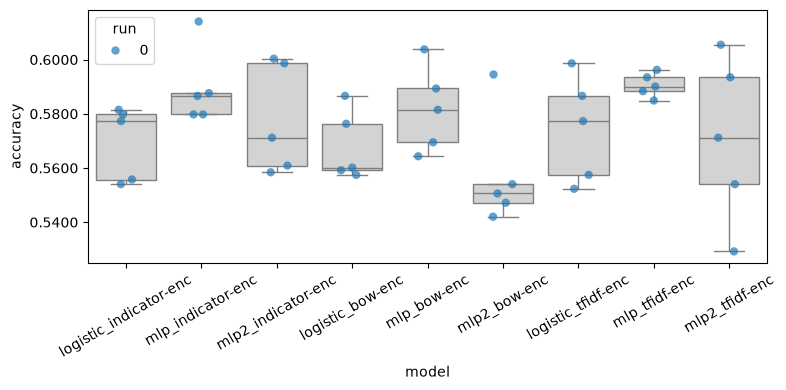

In [20]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [21]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.0135
P(Tie)    = 0.0419
P(B wins) = 0.9446
Effect Size = 2.73

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.2340
P(Tie)    = 0.1933
P(B wins) = 0.5727
Effect Size = 0.50

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.6868
P(Tie)    = 0.1838
P(B wins) = 0.1293
Effect Size = -0.92


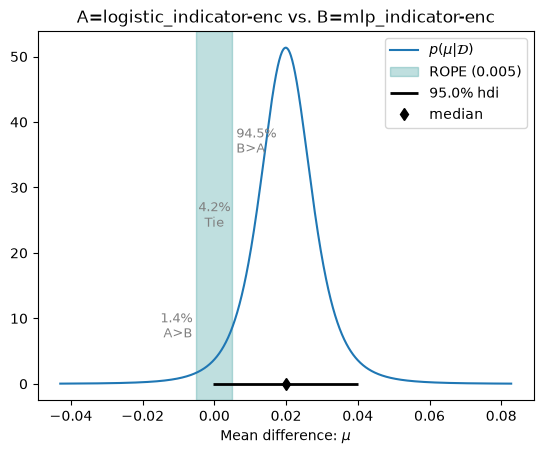

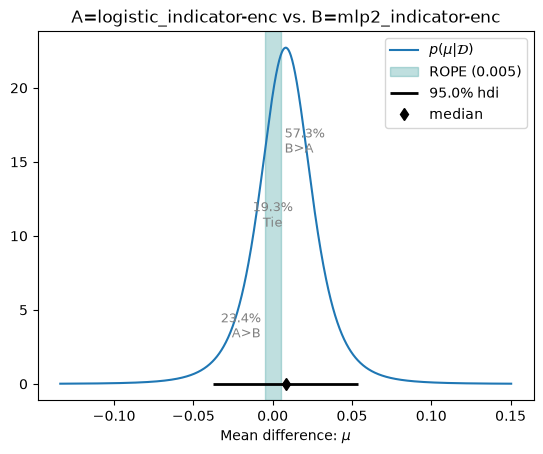

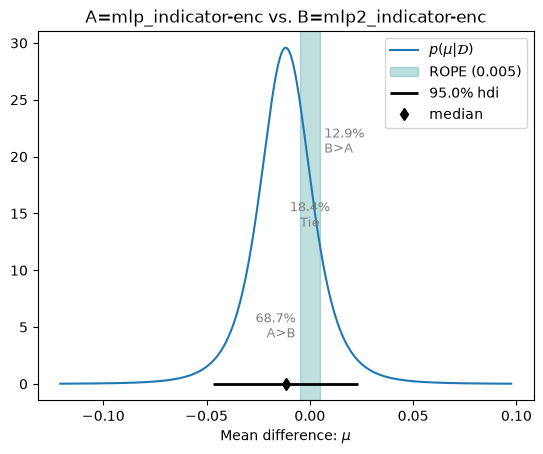

In [22]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [23]:

import Project1.smlp as smlp
import Project1.smlp2 as smlp2

# Find saved checkpoints from your cross-validation
def find_checkpoints(model_name):
    folder = results_folder / model_name / "seed-0"

    checkpoints = sorted(
        path.with_suffix("")
        for path in folder.rglob("*.pt")
        if path.with_suffix(".json").exists()
    )

    if not checkpoints:
        raise FileNotFoundError(
            f"No saved model checkpoints found in {folder}"
        )

    return checkpoints


mlp_checkpoints = find_checkpoints("mlp_indicator-enc")
mlp2_checkpoints = find_checkpoints("mlp2_indicator-enc")

print("Original MLP checkpoints:")
for i, path in enumerate(mlp_checkpoints):
    print(i, path)

print("\nModified MLP checkpoints:")
for i, path in enumerate(mlp2_checkpoints):
    print(i, path)


Original MLP checkpoints:
0 results/mlp_indicator-enc/seed-0/fold-0/model
1 results/mlp_indicator-enc/seed-0/fold-1/model
2 results/mlp_indicator-enc/seed-0/fold-2/model
3 results/mlp_indicator-enc/seed-0/fold-3/model
4 results/mlp_indicator-enc/seed-0/fold-4/model

Modified MLP checkpoints:
0 results/mlp2_indicator-enc/seed-0/fold-0/model
1 results/mlp2_indicator-enc/seed-0/fold-1/model
2 results/mlp2_indicator-enc/seed-0/fold-2/model
3 results/mlp2_indicator-enc/seed-0/fold-3/model
4 results/mlp2_indicator-enc/seed-0/fold-4/model


In [24]:
# Select corresponding checkpoints from the same fold
fold = 0

mlp_model = smlp.load(
    str(mlp_checkpoints[fold]),
    device="cpu"
)

mlp2_model = smlp2.load2(
    str(mlp2_checkpoints[fold]),
    device="cpu"
)

mlp_model.eval()
mlp2_model.eval()

print("Both MLP models loaded successfully!")

Both MLP models loaded successfully!


In [25]:
# Log-linear
def logistic_predict(texts, encoder):
    return Project1.loglin.predict_probs(
        texts,
        logistic_model,
        encoder
    )

for i, path in enumerate(mlp2_checkpoints):
    print(i, path)

# Original MLP
def mlp_predict(texts, encoder):
    return Project1.smlp.predict_probs(
        texts,
        mlp_model,
        encoder
    )

# Modified MLP (two hidden layers)
def mlp2_predict(texts, encoder):
    return Project1.smlp2.predict_probs2(
        texts,
        mlp2_model,
        encoder
    )

encoders = {token_indicator_encoder, bow_encoder, tfidf_encoder}

# Models for LIME
models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

0 results/mlp2_indicator-enc/seed-0/fold-0/model
1 results/mlp2_indicator-enc/seed-0/fold-1/model
2 results/mlp2_indicator-enc/seed-0/fold-2/model
3 results/mlp2_indicator-enc/seed-0/fold-3/model
4 results/mlp2_indicator-enc/seed-0/fold-4/model


In [26]:
tweet_id = 157
test_text = dataset["test"][tweet_id]
print(test_text)
print("Original MLP:", mlp_predict(test_text, token_indicator_encoder))
print("Modified MLP:", mlp2_predict(test_text, token_indicator_encoder))
print("Log-linear:", logistic_predict(test_text, token_indicator_encoder))

{'text': 'What about in cases of rape', 'label': 2}
Original MLP: [[0.3558916  0.3262316  0.31787685]
 [0.27715924 0.35937792 0.36346292]]
Modified MLP: [[0.34638107 0.32248256 0.3311364 ]
 [0.2489788  0.30562475 0.4453964 ]]
Log-linear: [[0.47022742 0.27330016 0.25647242]
 [0.28020619 0.21986241 0.4999314 ]]



Tweet 1: Where is the childcare program @user which you said would be in place? #loneparents #7istooyoung
True class: against

--- Log-linear ---
Prediction: against
Probabilities: [0.2957 0.586  0.1182]
Explanation: [(np.str_('7istooyoung'), 0.302243806379072), (np.str_('loneparents'), 0.29605825908004557), (np.str_('place'), -0.24163053822552327), (np.str_('user'), -0.191775112117419), (np.str_('would'), -0.15512491418583793), (np.str_('childcare'), 0.13168601613187453), (np.str_('be'), 0.08881238907147078), (np.str_('program'), -0.08832916528397593), (np.str_('in'), 0.06248102512442263), (np.str_('Where'), -0.05506508000819572)]


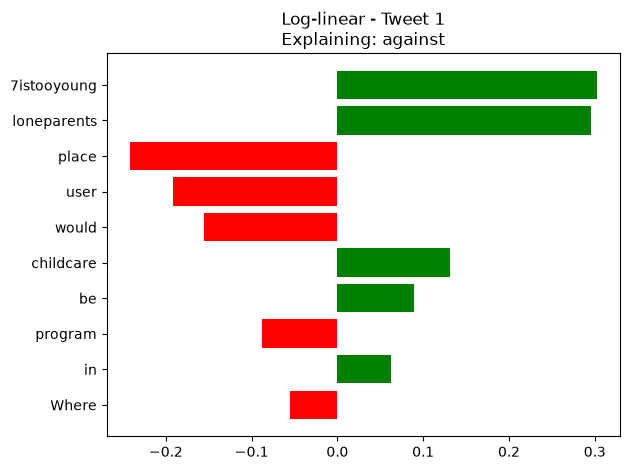


--- Original MLP ---
Prediction: against
Probabilities: [0.3353 0.5494 0.1153]
Explanation: [(np.str_('loneparents'), 0.10727978073894505), (np.str_('7istooyoung'), 0.08445109631936), (np.str_('childcare'), 0.08405978223047872), (np.str_('the'), 0.06485849513726295), (np.str_('place'), -0.05640814927728226), (np.str_('user'), -0.05286999008249988), (np.str_('be'), 0.041213533851258026), (np.str_('Where'), -0.031583813679464494), (np.str_('program'), -0.028187725248537004), (np.str_('would'), -0.021467366831042563)]


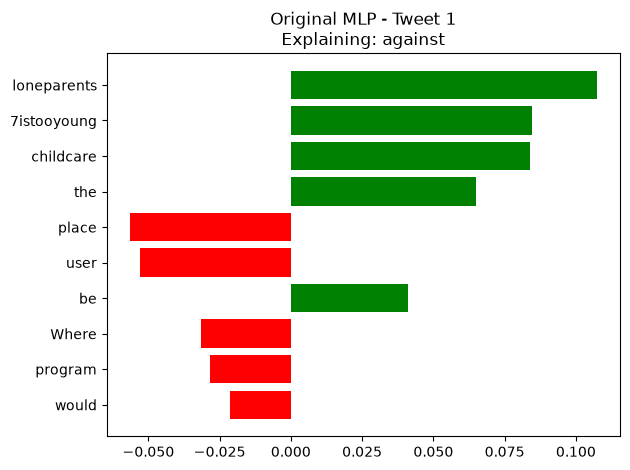


--- Modified MLP ---
Prediction: against
Probabilities: [0.2347 0.6686 0.0967]
Explanation: [(np.str_('loneparents'), 0.20255305140472862), (np.str_('7istooyoung'), 0.1996769538314631), (np.str_('childcare'), 0.18689687484434245), (np.str_('place'), -0.12018915088553095), (np.str_('user'), -0.11886681089738452), (np.str_('be'), 0.07823125935338668), (np.str_('which'), -0.05381034423269487), (np.str_('said'), -0.04758819356941428), (np.str_('program'), -0.0389304887829873), (np.str_('you'), -0.022866902891389224)]


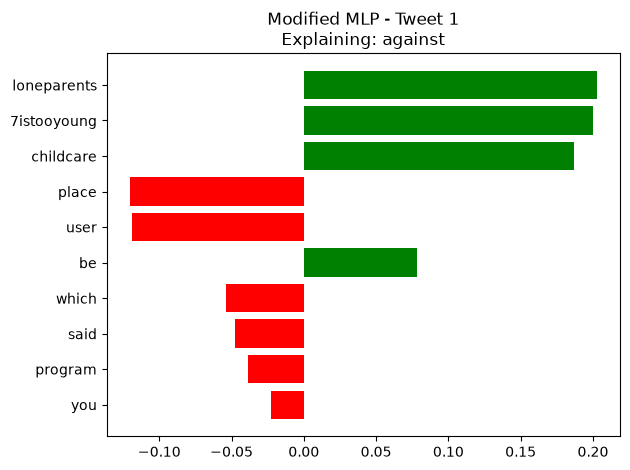


Tweet 8: Pray for the Navy yard. God please keep the casualties minimal.   #1A #2A #NRA #COS #CCOT #TGDN #PJNET  #WAKEUPAMERICA
True class: against

--- Log-linear ---
Prediction: against
Probabilities: [0.005 0.995 0.   ]
Explanation: [(np.str_('God'), 0.14280112645067816), (np.str_('please'), 0.11670272937298717), (np.str_('NRA'), 0.052004918497528446), (np.str_('TGDN'), -0.04991163062763538), (np.str_('casualties'), 0.048484695622575354), (np.str_('yard'), -0.04040703709678554), (np.str_('CCOT'), 0.03338193618163442), (np.str_('PJNET'), -0.019935112174289858), (np.str_('2A'), 0.018185971313357568), (np.str_('1A'), -0.015281640260940307)]


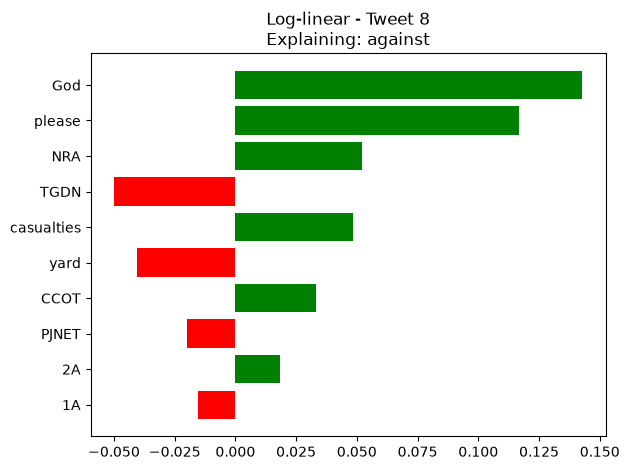


--- Original MLP ---
Prediction: against
Probabilities: [0.1441 0.834  0.0219]
Explanation: [(np.str_('God'), 0.13265698701203746), (np.str_('please'), 0.10550382863278333), (np.str_('casualties'), 0.07791710180993135), (np.str_('the'), 0.04978170530879321), (np.str_('yard'), -0.04678584562324819), (np.str_('Navy'), 0.044890393513976924), (np.str_('WAKEUPAMERICA'), -0.04190902764812377), (np.str_('1A'), -0.037459358443413124), (np.str_('PJNET'), 0.03548308250170806), (np.str_('NRA'), 0.03090521671641177)]


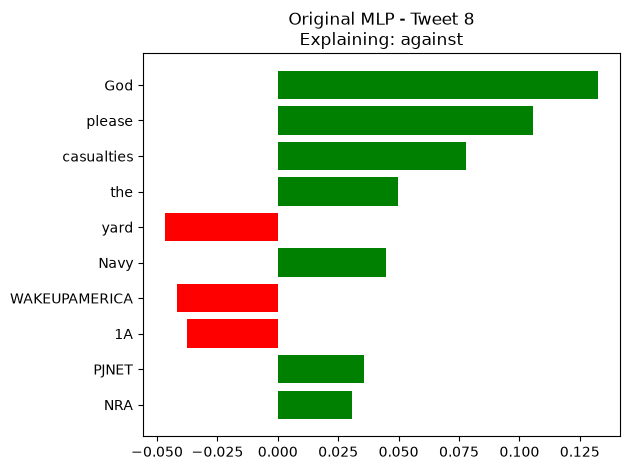


--- Modified MLP ---
Prediction: against
Probabilities: [0.1837 0.8148 0.0015]
Explanation: [(np.str_('God'), 0.2289577488455926), (np.str_('please'), 0.185880572832639), (np.str_('yard'), -0.12048590820201785), (np.str_('WAKEUPAMERICA'), -0.10289526531184831), (np.str_('TGDN'), -0.09259172345766233), (np.str_('CCOT'), 0.07549855088650441), (np.str_('NRA'), 0.07292144228243828), (np.str_('minimal'), -0.06425101937016998), (np.str_('PJNET'), 0.0616204692832851), (np.str_('1A'), -0.04986912775141186)]


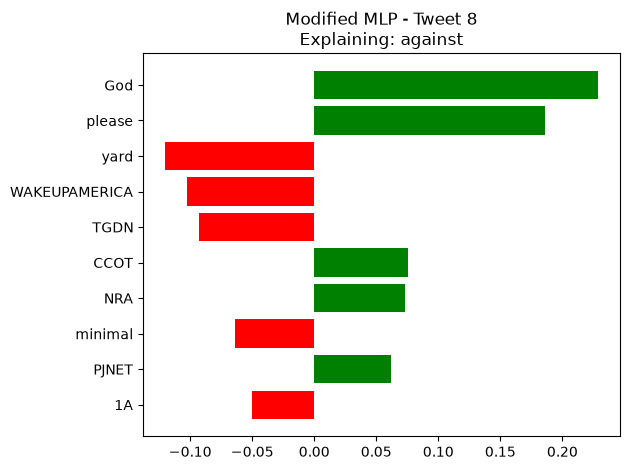


Tweet 157: What about in cases of rape
True class: favor

--- Log-linear ---
Prediction: favor
Probabilities: [0.2591 0.1596 0.5812]
Explanation: [(np.str_('What'), 0.19794095005031265), (np.str_('cases'), 0.1746290742381), (np.str_('about'), -0.09847203345030166), (np.str_('in'), 0.0474876067902517), (np.str_('of'), -0.04659441048555956), (np.str_('rape'), 0.020678437183896014)]


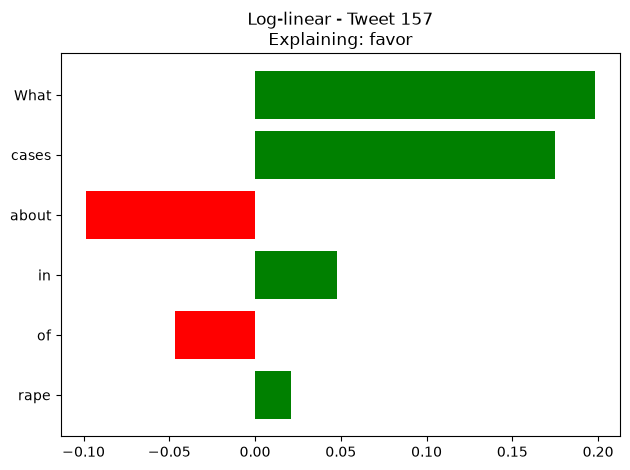


--- Original MLP ---
Prediction: favor
Probabilities: [0.265  0.3549 0.3801]
Explanation: [(np.str_('cases'), 0.0880599684753754), (np.str_('of'), -0.05052424928050077), (np.str_('What'), 0.026732929329545775), (np.str_('in'), 0.012408505442168751), (np.str_('about'), -0.007017254945902207), (np.str_('rape'), -0.006669879913902633)]


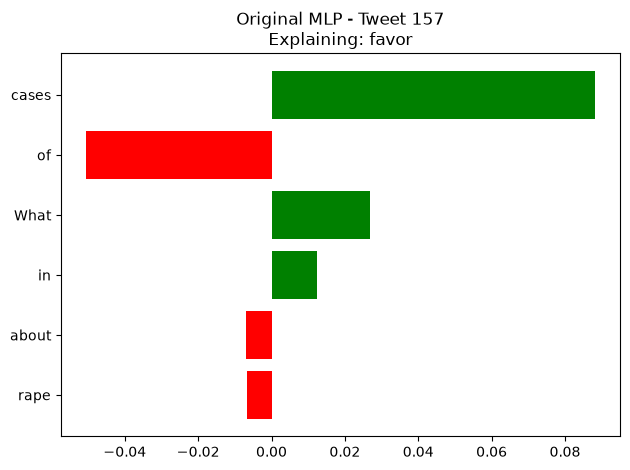


--- Modified MLP ---
Prediction: favor
Probabilities: [0.1692 0.339  0.4918]
Explanation: [(np.str_('cases'), 0.12552180334404206), (np.str_('What'), 0.08151212922268575), (np.str_('rape'), -0.04440586789301681), (np.str_('in'), 0.03595009182615659), (np.str_('of'), -0.019454586171015604), (np.str_('about'), -0.013991871672398164)]


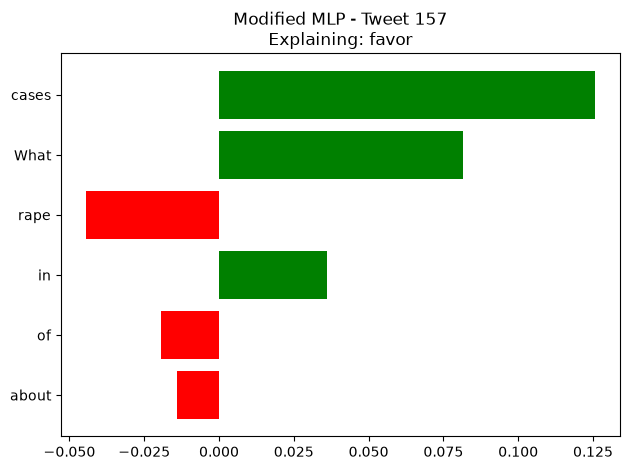

In [27]:
from lime.lime_text import LimeTextExplainer
from functools import partial

class_names = dataset["train"].features["label"].names

explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

models = {
    "Log-linear": partial(logistic_predict, encoder=token_indicator_encoder),
    "Original MLP": partial(mlp_predict, encoder=token_indicator_encoder),
    "Modified MLP": partial(mlp2_predict, encoder=token_indicator_encoder)
}

tweets = [1, 8, 157]

for tweet_id in tweets:

    example = dataset["test"][tweet_id]

    text = example["text"]
    true_label = int(example["label"])

    print(f"\n{'=' * 60}")
    print(f"Tweet {tweet_id}: {text}")
    print(f"True class: {class_names[true_label]}")

    for model_name, predict_fn in models.items():

        probabilities = predict_fn([text], encoder=token_indicator_encoder)[0]
        predicted_label = int(np.argmax(probabilities))

        # Explain the same target class across all models
        exp = explainer.explain_instance(
            text,
            predict_fn,
            num_features=10,
            num_samples=1000,
            labels=(true_label,)
        )

        print(f"\n--- {model_name} ---")
        print("Prediction:", class_names[predicted_label])
        print("Probabilities:", probabilities.round(4))
        print("Explanation:", exp.as_list(label=true_label))

        fig = exp.as_pyplot_figure(label=true_label)
        plt.title(
            f"{model_name} - Tweet {tweet_id}\n"
            f"Explaining: {class_names[true_label]}"
        )
        plt.tight_layout()
        plt.show()


In [28]:
# Collect cross-validation accuracy measurements
model_scores = {
    "Log-linear": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "MLP": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "Modified MLP": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Check the shapes
for name, scores in model_scores.items():
    print(name, scores.shape)

# Bayesian comparisons
results = []

for name_a, name_b in itertools.combinations(model_scores.keys(), 2):

    scores_a = np.asarray(model_scores[name_a], dtype=float)
    scores_b = np.asarray(model_scores[name_b], dtype=float)

    assert scores_a.shape == scores_b.shape, (
        "The models must have the same number of paired measurements."
    )

    posterior = Project1.analysis.BenavoliCorrelatedT(
        scores_a,
        scores_b,
        runs=1,  # Change if you used repeated cross-validation
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)

display(df.round(4))


Log-linear (5,)
MLP (5,)
Modified MLP (5,)


,Model A,Model B,P(A wins),P(Tie),P(B wins),Effect Size
0,Log-linear,MLP,0.0135,0.0419,0.9446,2.7254
1,Log-linear,Modified MLP,0.2340,0.1933,0.5727,0.4983
2,MLP,Modified MLP,0.6868,0.1838,0.1293,-0.9210


In [29]:
for topic in topics:
    topic_dataset = load_dataset("cardiffnlp/tweet_eval", topic)
    topic_test = topic_dataset["test"]
    texts = list(topic_test["text"])
    real_y = [int(label) for label in topic_test["label"]]

    rows = []
    for encoder in encoders:
        predictions = {
            "Logistic": logistic_predict(texts, encoder),
            "MLP": mlp_predict(texts, encoder),
            "MLP2": mlp2_predict(texts, encoder),
        }
        for model_name, pred_y in predictions.items():
            pred_labels = np.argmax(pred_y, axis=1)
            precision, recall, f1, _ = precision_recall_fscore_support(
                real_y, pred_labels, average="weighted", zero_division=0
            )
            rows.append({
                "Encoder": encoder.__class__.__name__,
                "Model": model_name,
                "Precision": precision,
                "Recall": recall,
                "F1 Score": f1,
            })

    metrics_df = pd.DataFrame(rows).set_index(["Encoder", "Model"])
    print(f"\nMetrics for topic: {topic}")
    display(metrics_df.round(4))


Metrics for topic: stance_abortion


Precision  Recall  F1 Score
Encoder        Model                                
tfidf          Logistic     0.5788  0.4357    0.4584
               MLP          0.6065  0.5893    0.5813
               MLP2         0.6196  0.3250    0.3236
BagOfWords     Logistic     0.5735  0.5643    0.5680
               MLP          0.6286  0.6536    0.6376
               MLP2         0.5949  0.5857    0.5897
TokenIndicator Logistic     0.5783  0.5714    0.5733
               MLP          0.6235  0.6536    0.6331
               MLP2         0.5794  0.5679    0.5720


Metrics for topic: stance_atheism


Precision  Recall  F1 Score
Encoder        Model                                
tfidf          Logistic     0.6554  0.3455    0.3854
               MLP          0.6902  0.5909    0.6138
               MLP2         0.7231  0.2864    0.3013
BagOfWords     Logistic     0.6389  0.5818    0.6018
               MLP          0.6265  0.6318    0.6291
               MLP2         0.6489  0.6227    0.6339
TokenIndicator Logistic     0.6425  0.5818    0.6039
               MLP          0.5975  0.6273    0.6113
               MLP2         0.6673  0.6455    0.6553


Metrics for topic: stance_climate


Precision  Recall  F1 Score
Encoder        Model                                
tfidf          Logistic     0.7481  0.3018    0.2792
               MLP          0.7101  0.3254    0.3351
               MLP2         0.6761  0.4497    0.4698
BagOfWords     Logistic     0.6702  0.4911    0.5501
               MLP          0.6907  0.4615    0.5320
               MLP2         0.6765  0.5089    0.5636
TokenIndicator Logistic     0.6557  0.4793    0.5373
               MLP          0.7026  0.4615    0.5356
               MLP2         0.6995  0.5385    0.5928


Metrics for topic: stance_feminist


Precision  Recall  F1 Score
Encoder        Model                                
tfidf          Logistic     0.6253  0.3930    0.4197
               MLP          0.5861  0.5158    0.5229
               MLP2         0.6127  0.2772    0.2715
BagOfWords     Logistic     0.5942  0.5614    0.5748
               MLP          0.5515  0.5649    0.5577
               MLP2         0.5919  0.5368    0.5581
TokenIndicator Logistic     0.5915  0.5614    0.5742
               MLP          0.5576  0.5754    0.5656
               MLP2         0.6059  0.5509    0.5699


Metrics for topic: stance_hillary


Precision  Recall  F1 Score
Encoder        Model                                
tfidf          Logistic     0.6124  0.5492    0.5358
               MLP          0.5915  0.6102    0.5778
               MLP2         0.5929  0.4102    0.3800
BagOfWords     Logistic     0.5687  0.5898    0.5745
               MLP          0.5571  0.5966    0.5566
               MLP2         0.5415  0.5593    0.5460
TokenIndicator Logistic     0.5637  0.5864    0.5686
               MLP          0.6000  0.6136    0.5718
               MLP2         0.5559  0.5763    0.5582

Transforming documents...
Document transformation done! Time taken: 0.316 seconds
Dataloader done! Time taken: 0.009 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0404 | train acc: 0.4715 | val loss: 1.0167 | val acc: 0.4768
Epoch 02 | train loss: 0.9050 | train acc: 0.5307 | val loss: 0.9391 | val acc: 0.5575
Epoch 03 | train loss: 0.7320 | train acc: 0.7229 | val loss: 0.8892 | val acc: 0.5883
Epoch 04 | train loss: 0.5718 | train acc: 0.8095 | val loss: 0.9041 | val acc: 0.5969
Epoch 05 | train loss: 0.4537 | train acc: 0.8580 | val loss: 0.9346 | val acc: 0.6003
Epoch 06 | train loss: 0.3663 | train acc: 0.8936 | val loss: 0.9700 | val acc: 0.5935
Epoch 07 | train loss: 0.2873 | train acc: 0.9309 | val loss: 1.0337 | val acc: 0.5883
Epoch 08 | train loss: 0.2284 | train acc: 0.9597 | val loss: 1.0764 | val acc: 0.5918
Epoch 09 | train loss: 0.1814 | train acc: 0.9747 | val loss: 1.1225 | val acc: 0.5866
Epoch 10 | train loss: 0.1435 | train acc: 0.9863 | val loss: 1.1802 | val acc: 0.5901
Epoch 11 | train loss: 0.1182 | train acc: 0.9910 | val loss: 1.2235 | val acc: 0.5798
Epoch 12 | train loss: 0.0963 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0457 | train acc: 0.4796 | val loss: 1.0273 | val acc: 0.4751
Epoch 02 | train loss: 0.9056 | train acc: 0.5401 | val loss: 0.9207 | val acc: 0.5643
Epoch 03 | train loss: 0.6160 | train acc: 0.7576 | val loss: 0.9716 | val acc: 0.5849
Epoch 04 | train loss: 0.3614 | train acc: 0.8709 | val loss: 1.1250 | val acc: 0.6003
Epoch 05 | train loss: 0.1857 | train acc: 0.9477 | val loss: 1.3454 | val acc: 0.5815
Epoch 06 | train loss: 0.0866 | train acc: 0.9854 | val loss: 1.5581 | val acc: 0.5969
Epoch 07 | train loss: 0.0415 | train acc: 0.9957 | val loss: 1.7074 | val acc: 0.5866
Epoch 08 | train loss: 0.0245 | train acc: 0.9974 | val loss: 1.8462 | val acc: 0.5780
Epoch 09 | train loss: 0.0151 | train acc: 0.9987 | val loss: 2.0188 | val acc: 0.5763
Epoch 10 | train loss: 0.0116 | train acc: 0.9987 | val loss: 2.1286 | val acc: 0.5643
Epoch 11 | train loss: 0.0089 | train acc: 0.9991 | val loss: 2.1631 | val acc: 0.5815
Epoch 12 | train loss: 0.0088 | train acc: 

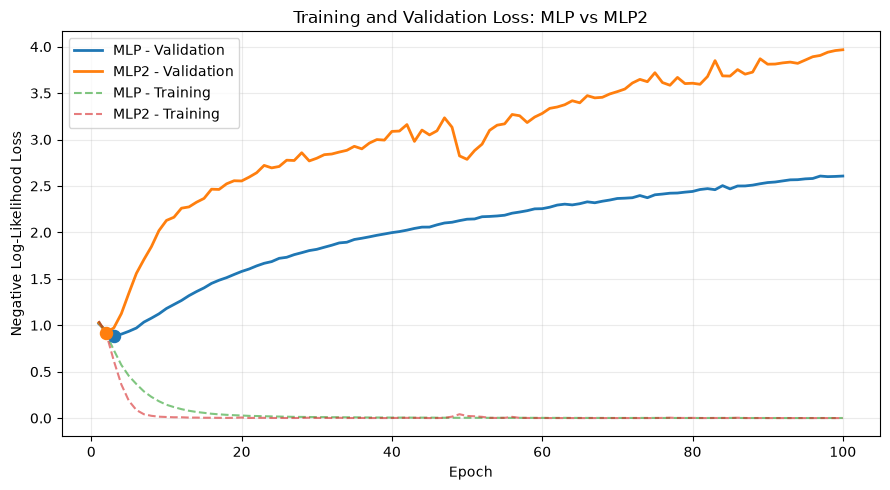

In [30]:
# Same training/validation fold for both architectures
fold_data = my_cross_validation_sets[0][0]

# Separate folder: don't overwrite original CV checkpoints
curve_folder = results_folder / "learning_curves"
curve_folder.mkdir(parents=True, exist_ok=True)

# Same hyperparameters as your original experiments
params = MLP_PARAMS

# Train original MLP
torch.manual_seed(42)
metrics_mlp, _, _ = smlp.train_neural_network_model(
    training_set=fold_data["training"],
    validation_set=fold_data["validation"],
    num_classes=len(outcome_space),
    encoder=token_indicator_encoder,
    save_to=str(curve_folder / "mlp"),
    **params
)

# Train modified MLP
torch.manual_seed(42)
metrics_mlp2, _, _ = smlp2.train_neural_network_model2(
    training_set=fold_data["training"],
    validation_set=fold_data["validation"],
    num_classes=len(outcome_space),
    encoder=token_indicator_encoder,
    save_to=str(curve_folder / "mlp2"),
    **params
)

# Extract losses
train_mlp = [m["train_metrics"]["loss"] for m in metrics_mlp]
val_mlp = [m["val_metrics"]["loss"] for m in metrics_mlp]

train_mlp2 = [m["train_metrics"]["loss"] for m in metrics_mlp2]
val_mlp2 = [m["val_metrics"]["loss"] for m in metrics_mlp2]

epochs = np.arange(1, len(val_mlp) + 1)

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(epochs, val_mlp, label="MLP - Validation", linewidth=2)
ax.plot(epochs, val_mlp2, label="MLP2 - Validation", linewidth=2)

ax.plot(epochs, train_mlp, "--", label="MLP - Training", alpha=0.6)
ax.plot(epochs, train_mlp2, "--", label="MLP2 - Training", alpha=0.6)

# Highlight best validation epoch
for name, losses, line_index in [
    ("MLP", val_mlp, 0),
    ("MLP2", val_mlp2, 1)
]:
    best = int(np.argmin(losses))
    color = ax.lines[line_index].get_color()

    ax.scatter(
        best + 1, losses[best],
        color=color, s=75, zorder=5
    )

    print(
        f"{name}: best epoch = {best + 1}, "
        f"minimum validation loss = {losses[best]:.4f}"
    )

ax.set_title("Training and Validation Loss: MLP vs MLP2")
ax.set_xlabel("Epoch")
ax.set_ylabel("Negative Log-Likelihood Loss")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("mlp_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()
